In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set(style="whitegrid", palette="muted")

In [5]:
df=pd.read_csv(r"C:\Users\dsi\Documents\M17_Project_Pima_Indians_Diabetes\Data\diabetes.csv")
df_copy=df.copy()

In [6]:
print(df_copy.head())
print(df_copy.shape)
print(df_copy.info())
print(df_copy.describe())
print(df_copy.isnull().sum())


   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
(768, 9)
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 n

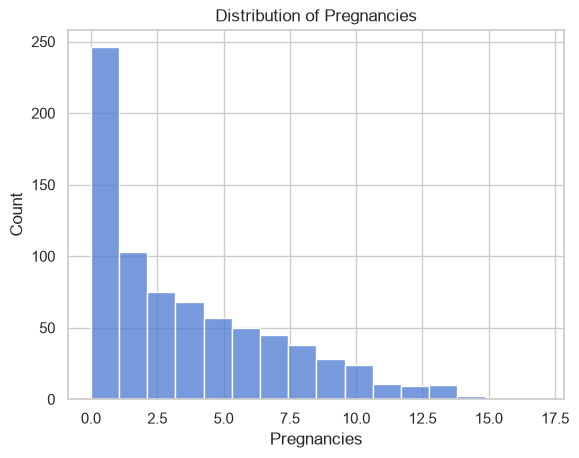

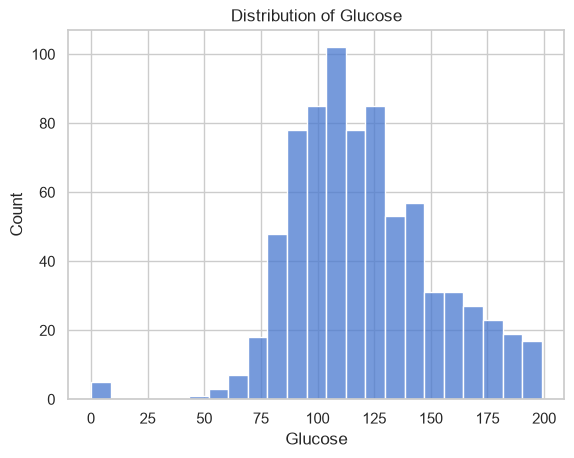

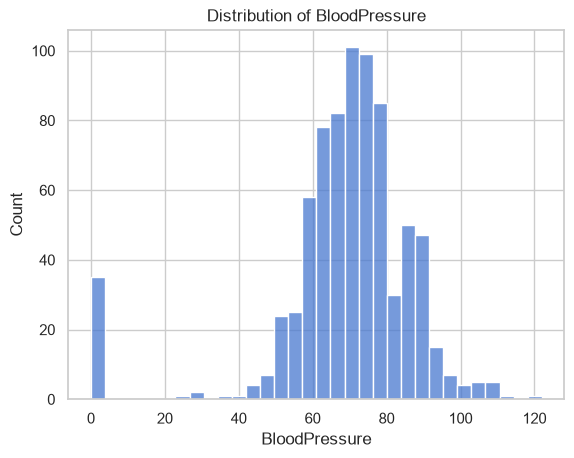

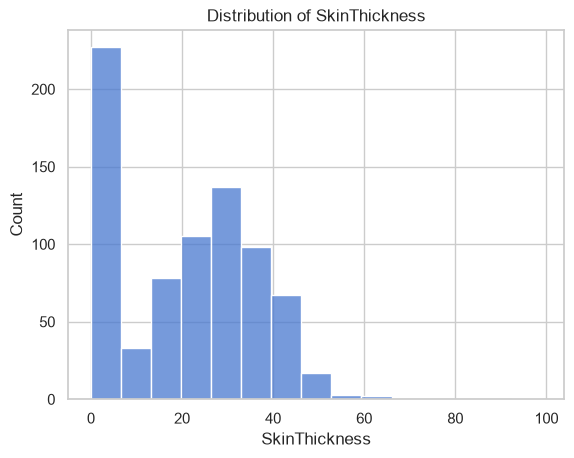

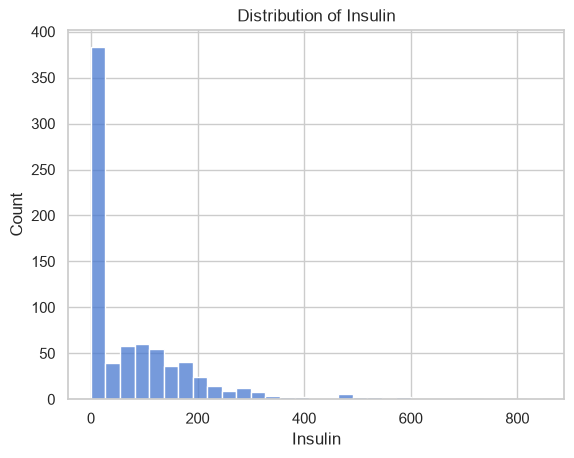

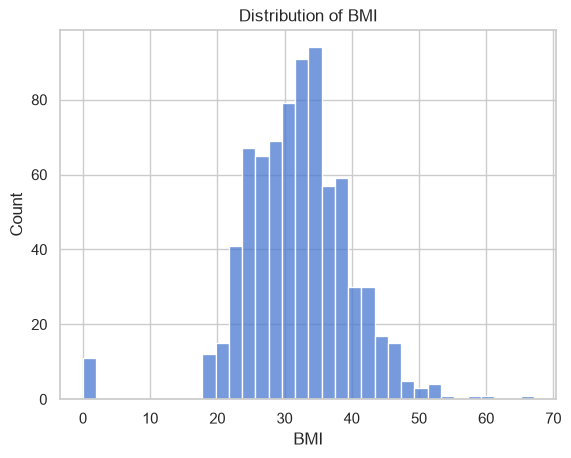

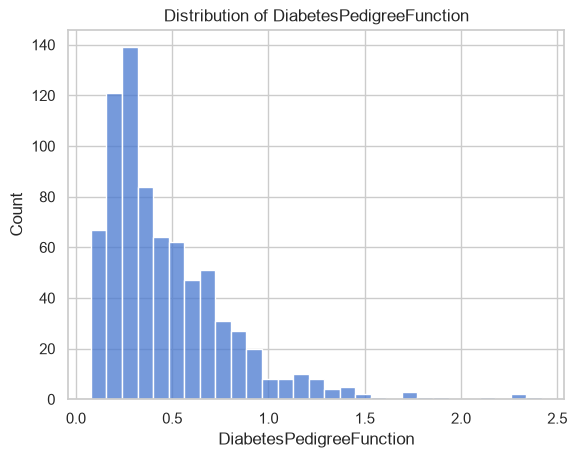

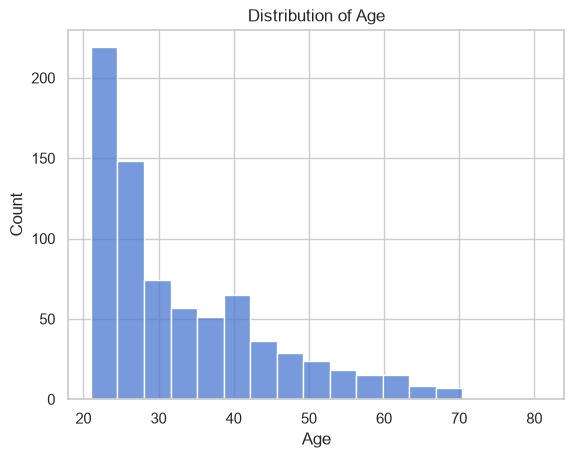

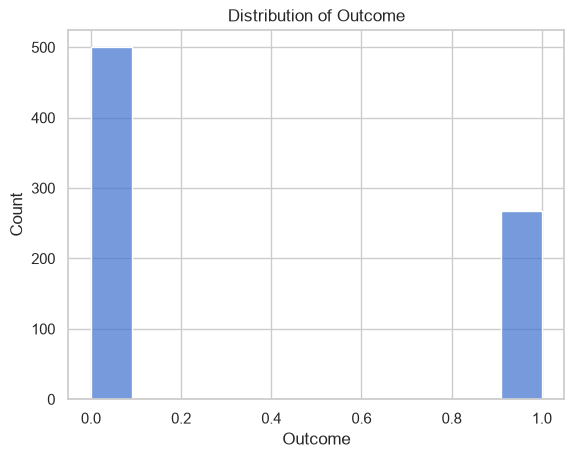

In [40]:

for col in df_copy.columns:
    sns.histplot(data=df_copy, x=col)
    plt.title(f"Distribution of {col}")
    plt.show()

In [42]:
df_copy.groupby("Outcome")["Insulin"].describe()

,count,mean,std,min,25%,50%,75%,max
Outcome,,,,,,,,
0,500.0,68.792000,98.865289,0.0,0.0,39.0,105.00,744.0
1,268.0,100.335821,138.689125,0.0,0.0,0.0,167.25,846.0


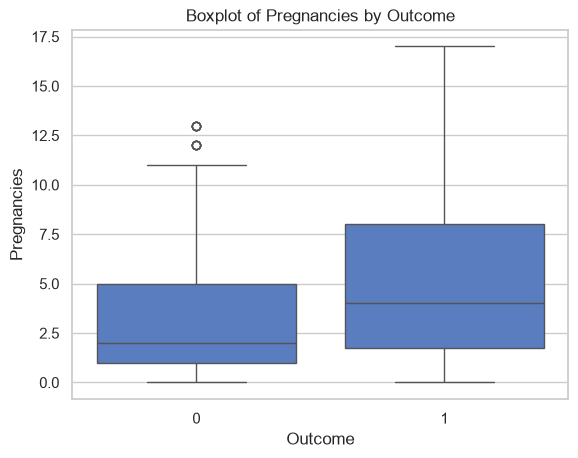

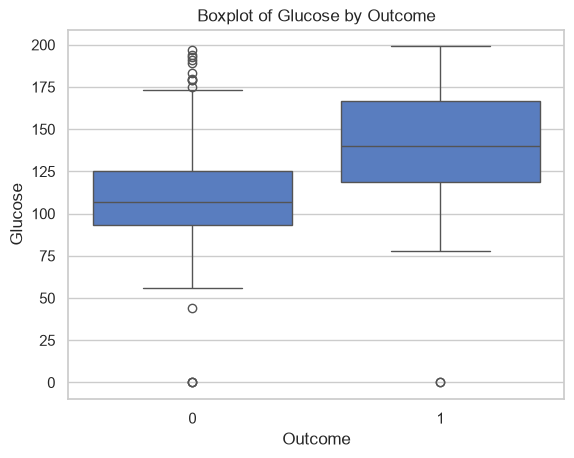

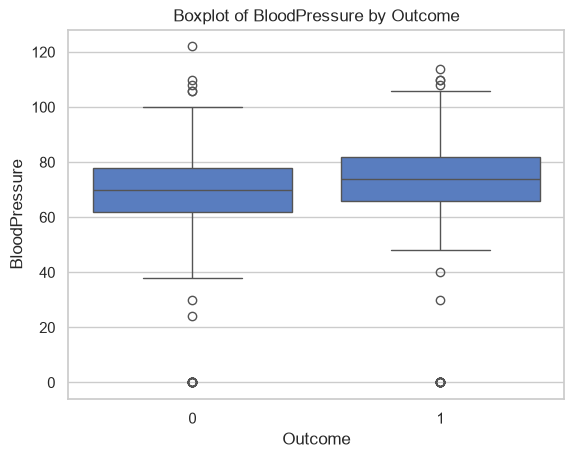

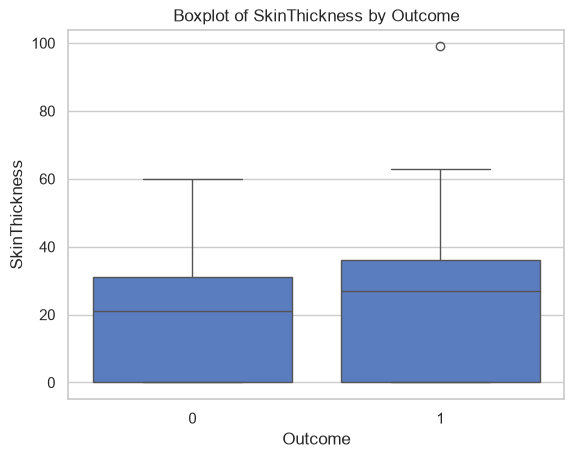

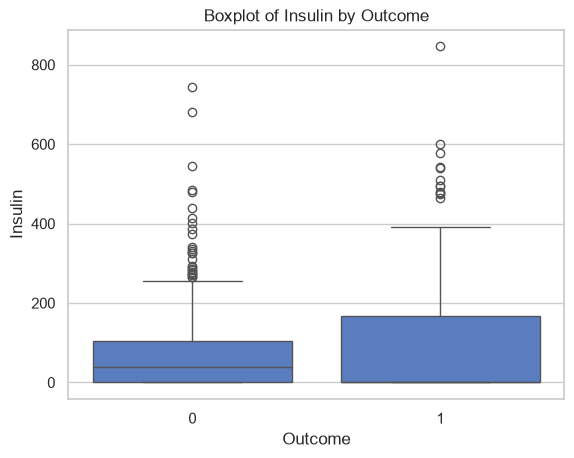

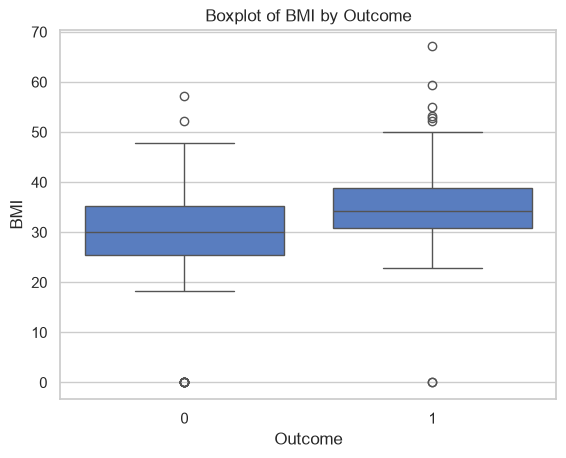

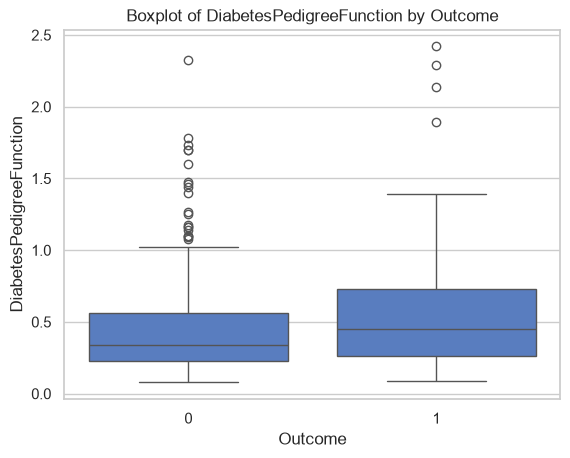

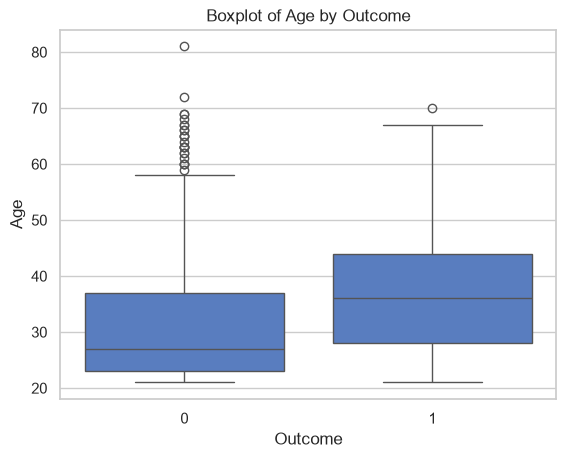

In [43]:
for col in df_copy.columns:
    if col != "Outcome":
        sns.boxplot(x="Outcome", y=col, data=df_copy)
        plt.title(f"Boxplot of {col} by Outcome")
        plt.show()

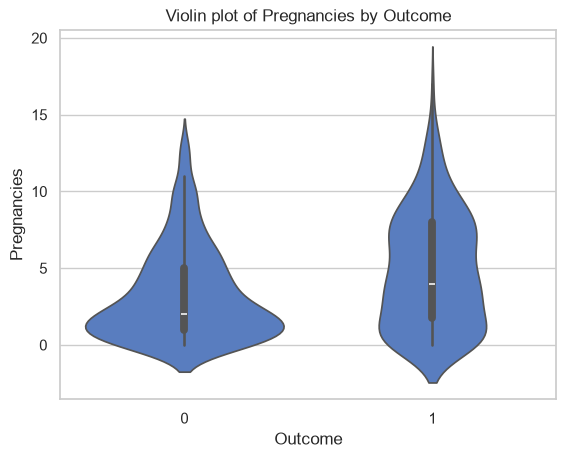

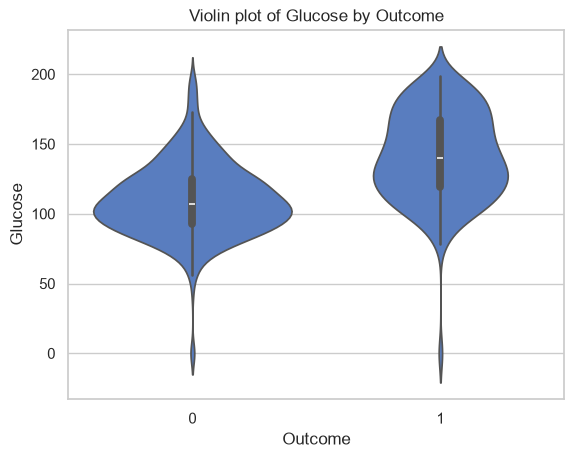

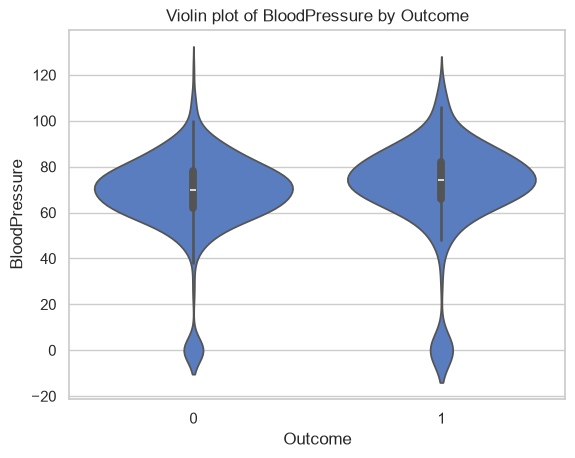

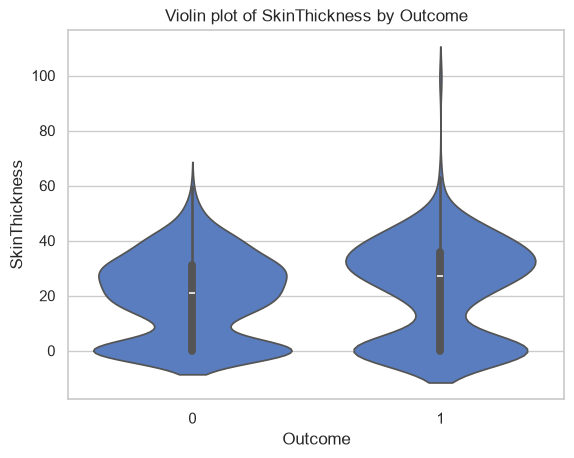

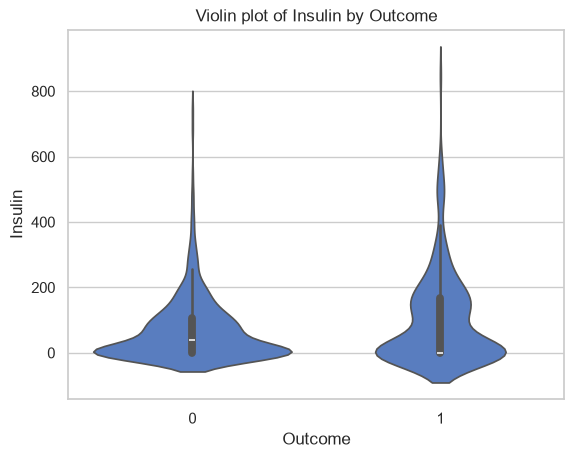

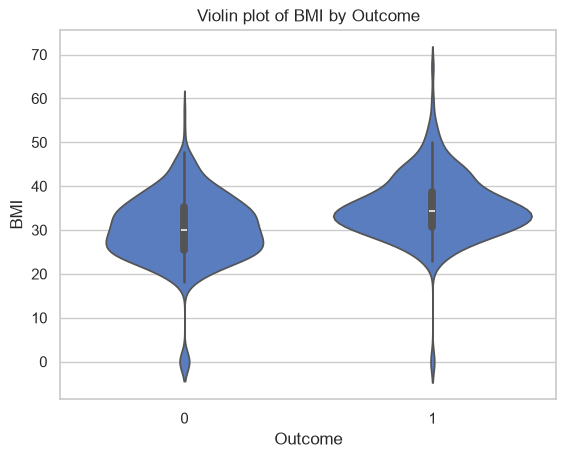

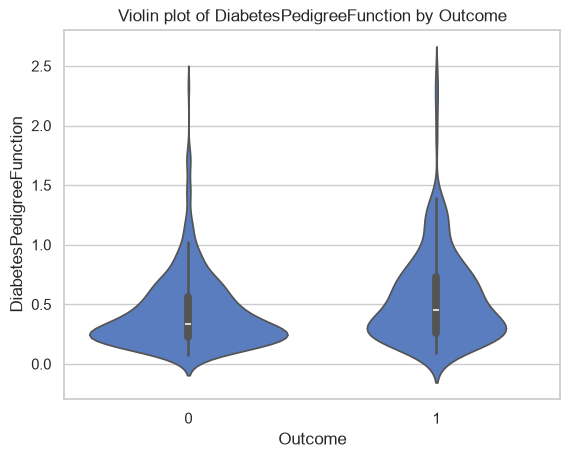

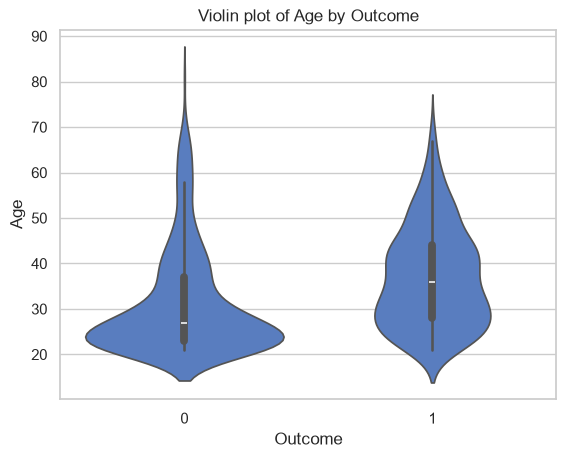

In [44]:
for col in df_copy.columns:
    if col != "Outcome":
        sns.violinplot(x="Outcome", y=col, data=df_copy)
        plt.title(f"Violin plot of {col} by Outcome")
        plt.show()

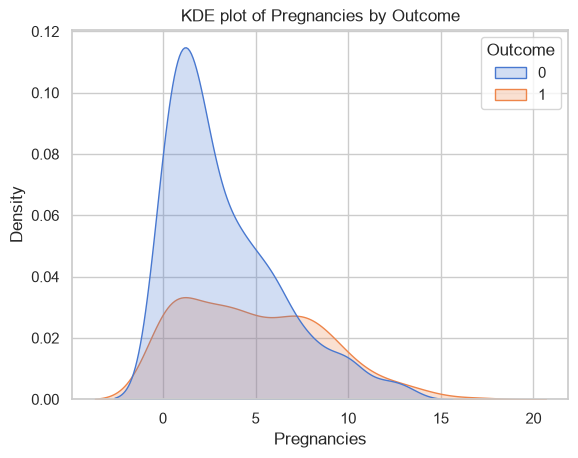

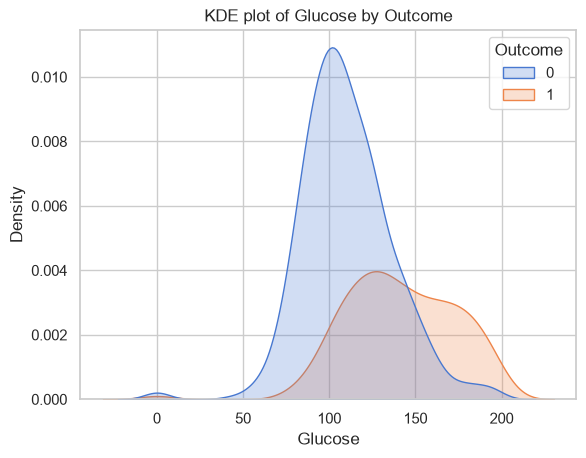

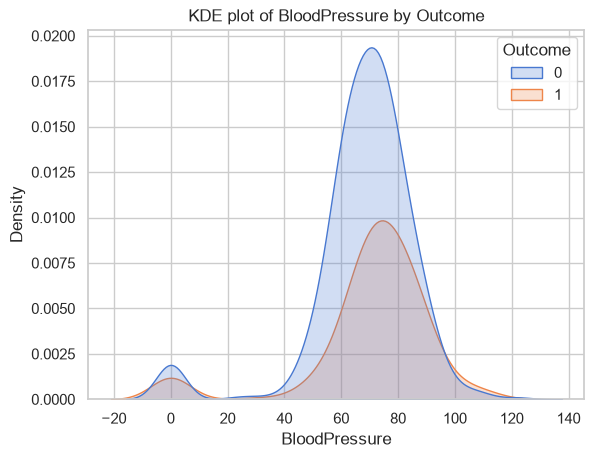

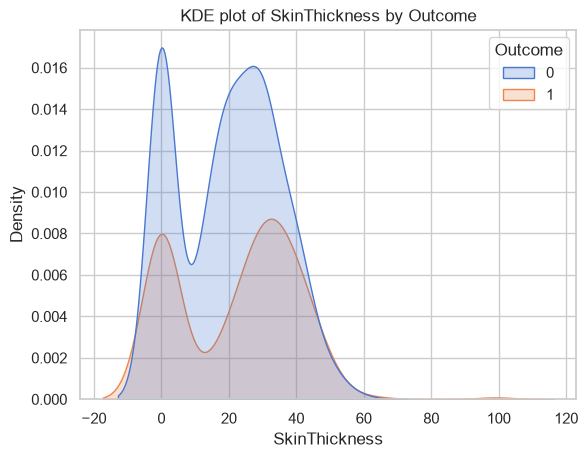

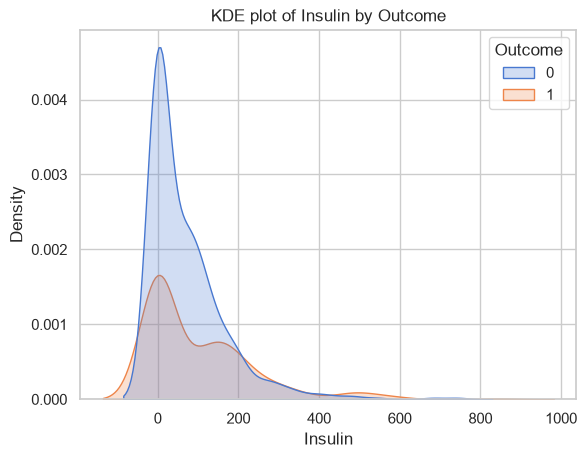

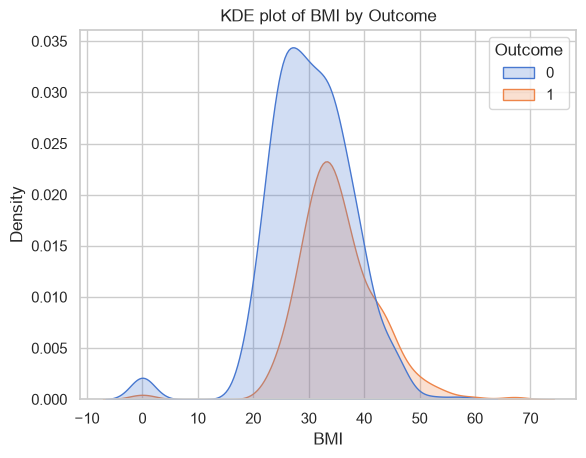

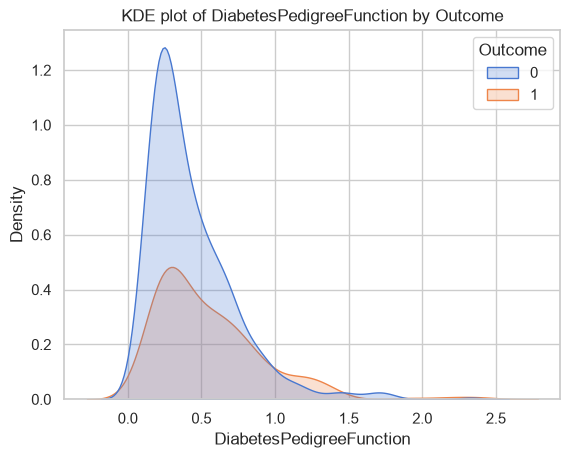

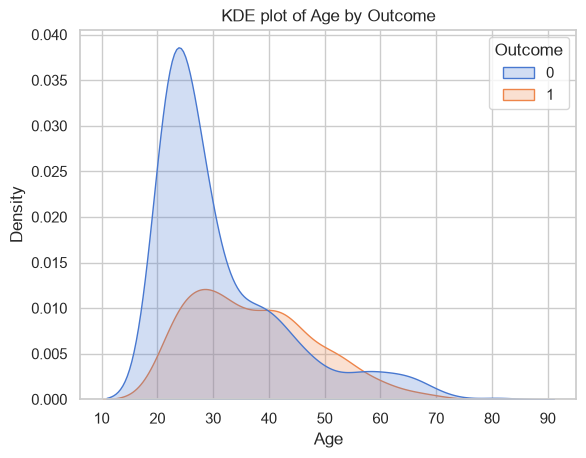

In [45]:
for col in df_copy.columns:
    if col != "Outcome":
        sns.kdeplot(data=df_copy, x=col, hue="Outcome", fill=True)
        plt.title(f"KDE plot of {col} by Outcome")
        plt.show()

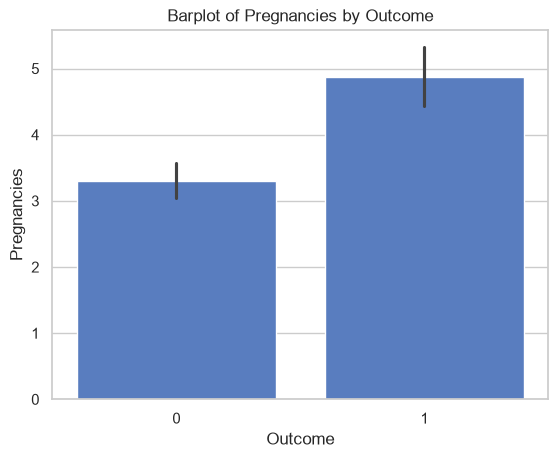

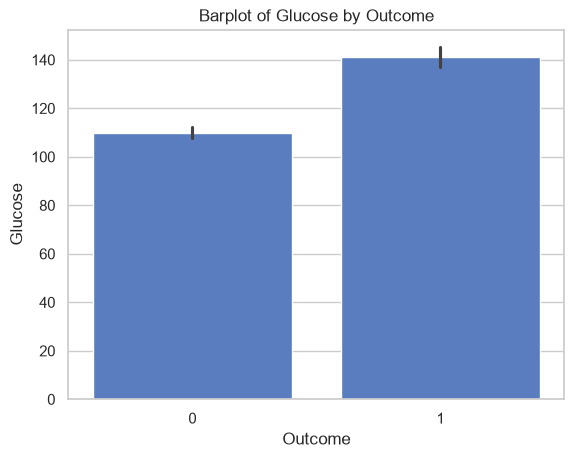

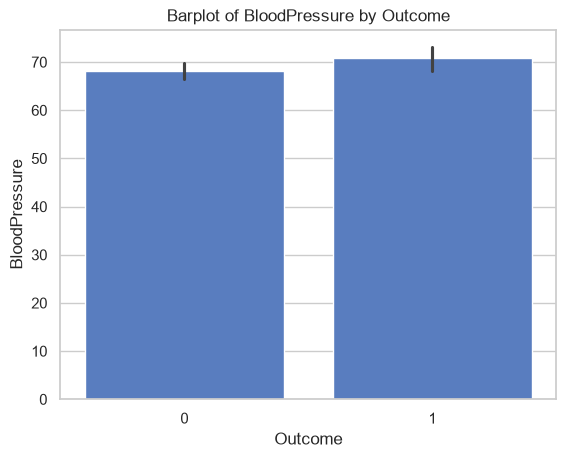

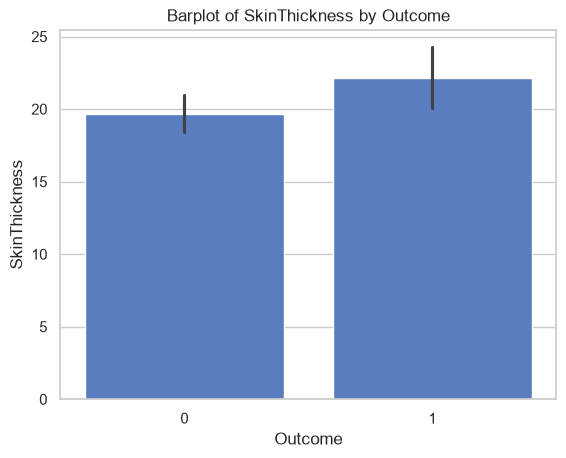

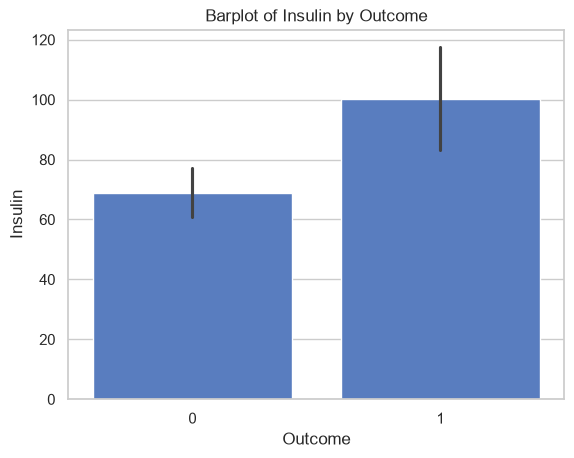

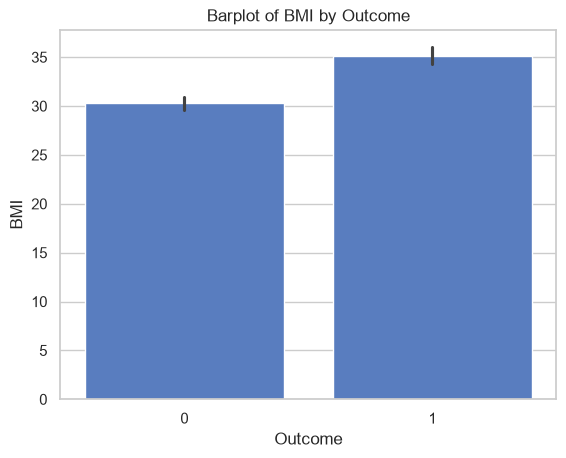

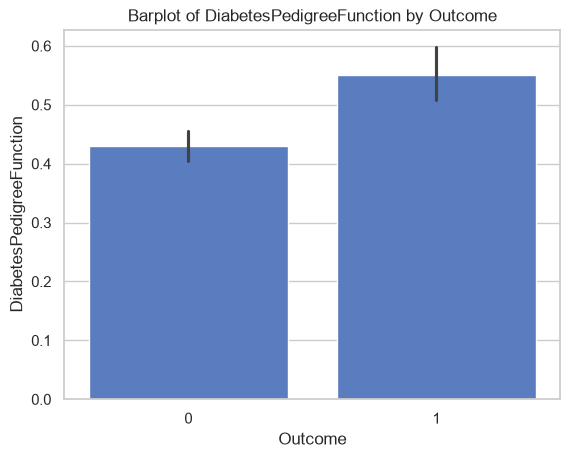

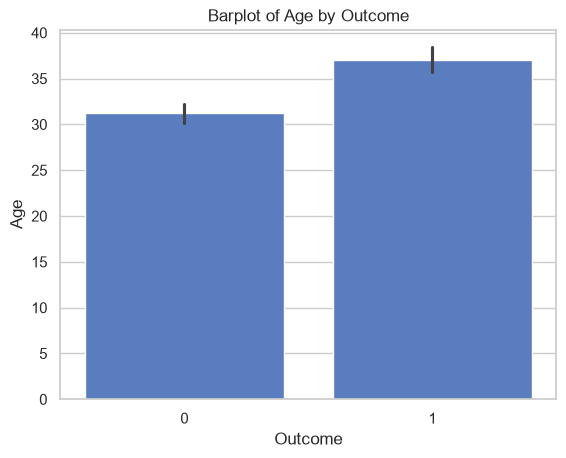

In [ ]:
for col in df_copy.columns:
    if col != "Outcome":
        sns.barplot(data=df_copy, x="Outcome", y=col)
        plt.title(f"Barplot of {col} by Outcome")

        plt.show()

In [53]:
for col in df_copy.columns: 
    print(f"Description of {col} by Outcome:")
    print(df_copy.groupby("Outcome")[col].describe())

Description of Pregnancies by Outcome:
         count      mean       std  min   25%  50%  75%   max
Outcome                                                      
0        500.0  3.298000  3.017185  0.0  1.00  2.0  5.0  13.0
1        268.0  4.865672  3.741239  0.0  1.75  4.0  8.0  17.0
Description of Glucose by Outcome:
         count        mean        std  min    25%    50%    75%    max
Outcome                                                               
0        500.0  109.980000  26.141200  0.0   93.0  107.0  125.0  197.0
1        268.0  141.257463  31.939622  0.0  119.0  140.0  167.0  199.0
Description of BloodPressure by Outcome:
         count       mean        std  min   25%   50%   75%    max
Outcome                                                           
0        500.0  68.184000  18.063075  0.0  62.0  70.0  78.0  122.0
1        268.0  70.824627  21.491812  0.0  66.0  74.0  82.0  114.0
Description of SkinThickness by Outcome:
         count       mean        std  min  2

In [54]:
for col in df_copy.select_dtypes(include="object").columns:
    n_blank = df_copy[col].astype("string").str.strip().eq("").sum()
    if n_blank:
        print(col, n_blank)

In [55]:
df_copy.duplicated().sum()
df_copy[df_copy.duplicated(keep=False)]


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome


In [64]:
df_copy.sample(frac=0.01, random_state=42, replace=False).reset_index(drop=True)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,98,58,33,190,34.0,0.430,43,0
1,2,112,75,32,0,35.7,0.148,21,0
2,2,108,64,0,0,30.8,0.158,21,0
3,8,107,80,0,0,24.6,0.856,34,0
4,7,136,90,0,0,29.9,0.210,50,0
5,6,103,72,32,190,37.7,0.324,55,0
6,1,71,48,18,76,20.4,0.323,22,0
7,0,117,0,0,0,33.8,0.932,44,0


In [73]:
df_copy.corr()["Outcome"].sort_values(ascending=False)

Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64

<Axes: >

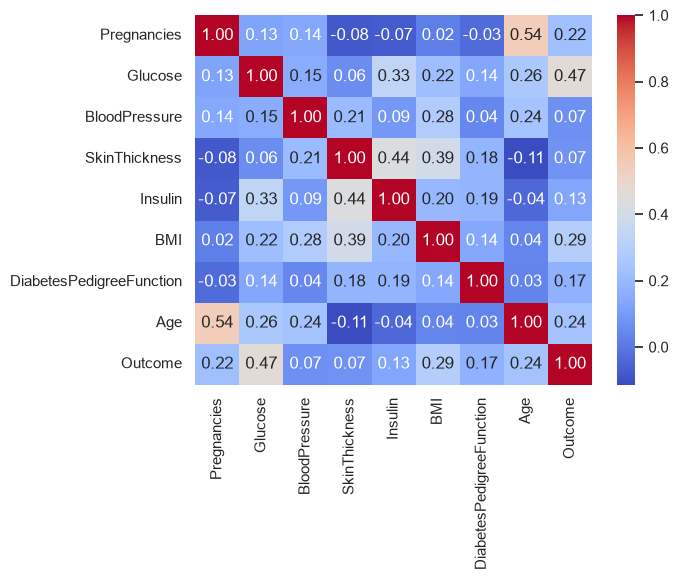

In [78]:
sns.heatmap(df_copy.corr(), annot=True, cmap="coolwarm", fmt=".2f")

<Axes: xlabel='Outcome', ylabel='Glucose'>

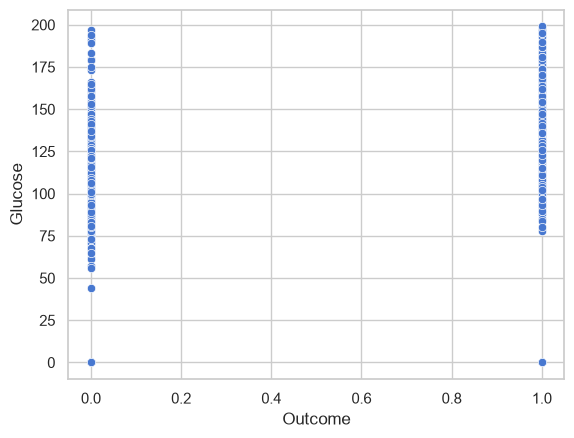

In [86]:
sns.scatterplot(data=df_copy,y="Glucose",x="Outcome")

In [87]:
df_copy.groupby('Outcome')['Glucose'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
Outcome,,,,
0,500,109.980000,107.0,26.141200
1,268,141.257463,140.0,31.939622


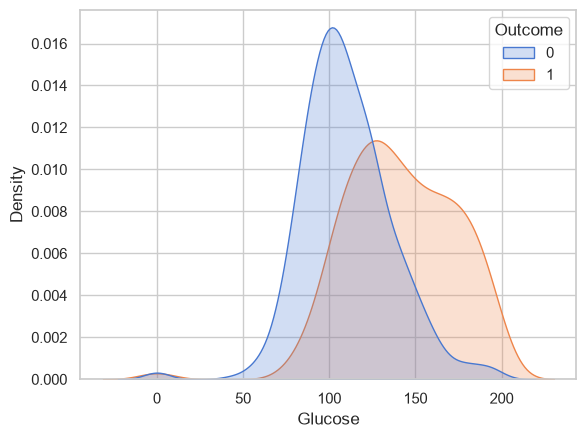

In [88]:
sns.kdeplot(
    data=df,
    x='Glucose',
    hue='Outcome',
    fill=True,
    common_norm=False
)
plt.show()

In [89]:
df.groupby(
    pd.cut(df['Glucose'], bins=10),
    observed=True
)['Outcome'].mean() * 100

Glucose
(-0.199, 19.9]    40.000000
(39.8, 59.7]       0.000000
(59.7, 79.6]       3.125000
(79.6, 99.5]       8.333333
(99.5, 119.4]     25.592417
(119.4, 139.3]    38.650307
(139.3, 159.2]    53.684211
(159.2, 179.1]    80.357143
(179.1, 199.0]    84.782609
Name: Outcome, dtype: float64